In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("cleaned_customer_data.csv")

print(df.head())
print("Dataset Shape:", df.shape)

Matplotlib is building the font cache; this may take a moment.


     ID  Year_Birth   Education Marital_Status   Income  Kidhome  Teenhome  \
0  5524        1957  Graduation         Single  58138.0        0         0   
1  2174        1954  Graduation         Single  46344.0        1         1   
2  4141        1965  Graduation       Together  71613.0        0         0   
3  6182        1984  Graduation       Together  26646.0        1         0   
4  5324        1981         PhD        Married  58293.0        1         0   

  Dt_Customer  Recency  MntWines  ...  AcceptedCmp3  AcceptedCmp4  \
0  2012-09-04       58       635  ...             0             0   
1  2014-03-08       38        11  ...             0             0   
2  2013-08-21       26       426  ...             0             0   
3  2014-02-10       26        11  ...             0             0   
4  2014-01-19       94       173  ...             0             0   

   AcceptedCmp5  AcceptedCmp1  AcceptedCmp2  Complain  Z_CostContact  \
0             0             0             0 

In [2]:
print("Average Income:", df["Income"].mean())

print("Median Income:", df["Income"].median())

print("Minimum Income:", df["Income"].min())

print("Maximum Income:", df["Income"].max())

Average Income: 52237.97544642857
Median Income: 51381.5
Minimum Income: 1730.0
Maximum Income: 666666.0


In [3]:
df["Age"] = 2024 - df["Year_Birth"]

print("Average Age:", df["Age"].mean())
print("Median Age:", df["Age"].median())
print("Minimum Age:", df["Age"].min())
print("Maximum Age:", df["Age"].max())

Average Age: 55.19419642857143
Median Age: 54.0
Minimum Age: 28
Maximum Age: 131


In [4]:
df["Age_Group"] = pd.cut(
    df["Age"],
    bins=[0, 25, 35, 45, 55, 65, 100, 200],
    labels=["Under 25", "26-35", "36-45", "46-55",
            "56-65", "66-100", "Above 100"]
)

print(df["Age_Group"].value_counts().sort_index())

Age_Group
Under 25       0
26-35         91
36-45        386
46-55        758
56-65        486
66-100       516
Above 100      3
Name: count, dtype: int64


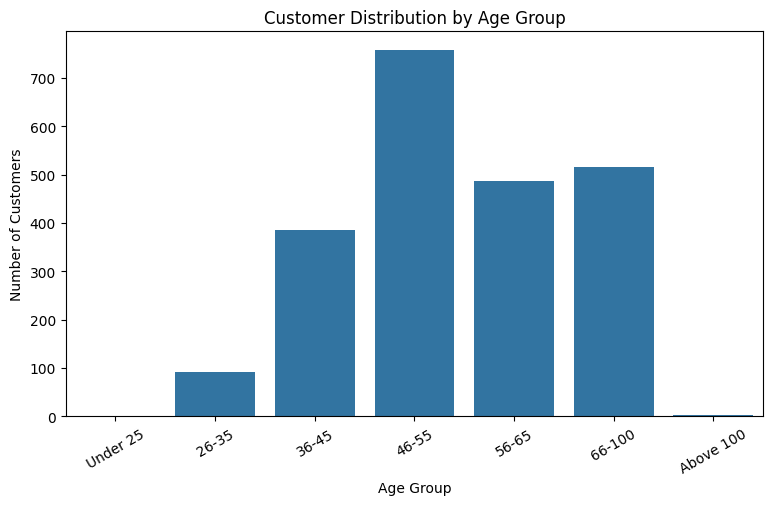

In [5]:
plt.figure(figsize=(9, 5))

sns.countplot(data=df, x="Age_Group")

plt.title("Customer Distribution by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Number of Customers")
plt.xticks(rotation=30)

plt.show()

In [6]:
spending_columns = [
    "MntWines",
    "MntFruits",
    "MntMeatProducts",
    "MntFishProducts",
    "MntSweetProducts",
    "MntGoldProds"
]

df["Total_Spending"] = df[spending_columns].sum(axis=1)

print("Average Customer Spending:", df["Total_Spending"].mean())
print("Highest Customer Spending:", df["Total_Spending"].max())
print("Lowest Customer Spending:", df["Total_Spending"].min())

Average Customer Spending: 605.7982142857143
Highest Customer Spending: 2525
Lowest Customer Spending: 5


In [7]:
category_spending = df[spending_columns].sum().sort_values(ascending=False)

print(category_spending)


MntWines            680816
MntMeatProducts     373968
MntGoldProds         98609
MntFishProducts      84057
MntSweetProducts     60621
MntFruits            58917
dtype: int64


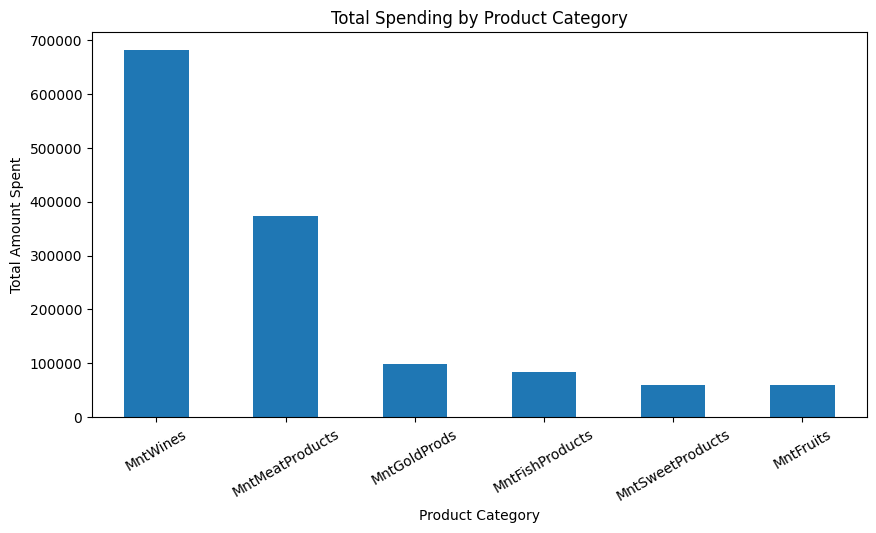

In [8]:
plt.figure(figsize=(10, 5))

category_spending.plot(kind="bar")

plt.title("Total Spending by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Amount Spent")
plt.xticks(rotation=30)

plt.show()

In [9]:
purchase_columns = [
    "NumWebPurchases",
    "NumCatalogPurchases",
    "NumStorePurchases"
]

channel_purchases = df[purchase_columns].sum()

print("Purchases by Channel:")
print(channel_purchases)

Purchases by Channel:
NumWebPurchases         9150
NumCatalogPurchases     5963
NumStorePurchases      12970
dtype: int64


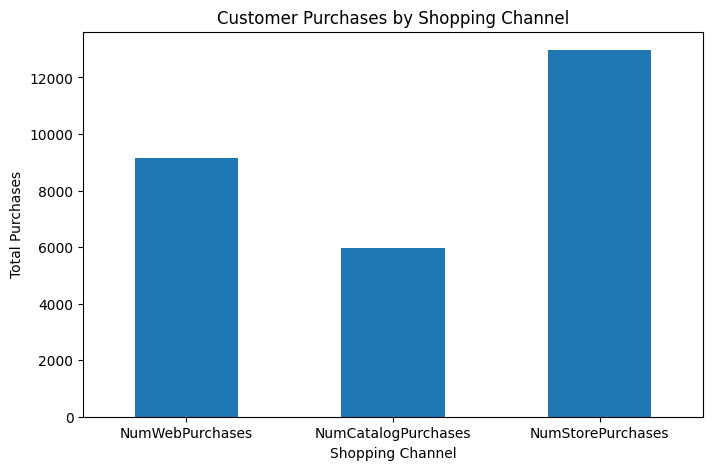

In [10]:
plt.figure(figsize=(8, 5))

channel_purchases.plot(kind="bar")

plt.title("Customer Purchases by Shopping Channel")
plt.xlabel("Shopping Channel")
plt.ylabel("Total Purchases")
plt.xticks(rotation=0)

plt.show()

In [11]:
print("Average Deal Purchases:",
      df["NumDealsPurchases"].mean())

print("Maximum Deal Purchases:",
      df["NumDealsPurchases"].max())

print("Average Website Visits:",
      df["NumWebVisitsMonth"].mean())

Average Deal Purchases: 2.325
Maximum Deal Purchases: 15
Average Website Visits: 5.316517857142857


In [12]:
campaign_columns = [
    "AcceptedCmp1",
    "AcceptedCmp2",
    "AcceptedCmp3",
    "AcceptedCmp4",
    "AcceptedCmp5",
    "Response"
]

campaign_results = df[campaign_columns].sum()

print("Campaign Acceptance:")
print(campaign_results)

Campaign Acceptance:
AcceptedCmp1    144
AcceptedCmp2     30
AcceptedCmp3    163
AcceptedCmp4    167
AcceptedCmp5    163
Response        334
dtype: int64


In [13]:
campaign_percentage = (
    df[campaign_columns].mean() * 100
).round(2)

print("Campaign Acceptance Percentage:")
print(campaign_percentage)


Campaign Acceptance Percentage:
AcceptedCmp1     6.43
AcceptedCmp2     1.34
AcceptedCmp3     7.28
AcceptedCmp4     7.46
AcceptedCmp5     7.28
Response        14.91
dtype: float64


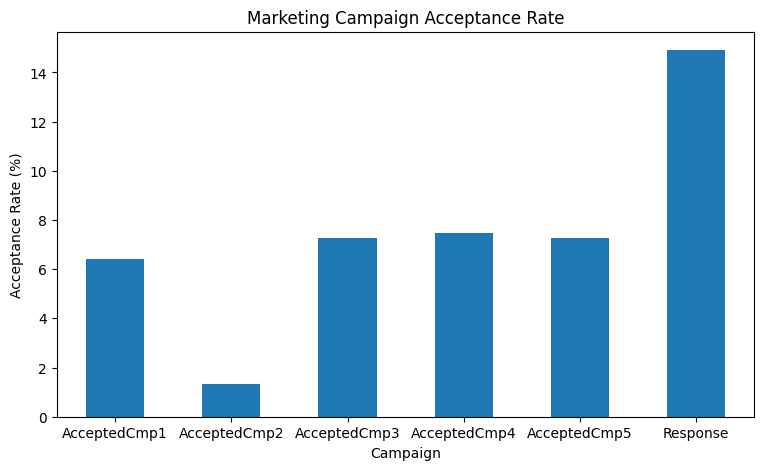

In [14]:
plt.figure(figsize=(9, 5))

campaign_percentage.plot(kind="bar")

plt.title("Marketing Campaign Acceptance Rate")
plt.xlabel("Campaign")
plt.ylabel("Acceptance Rate (%)")
plt.xticks(rotation=0)

plt.show()

In [15]:
education_counts = df["Education"].value_counts()

print("Customers by Education:")
print(education_counts)

Customers by Education:
Education
Graduation    1127
PhD            486
Master         370
2n Cycle       203
Basic           54
Name: count, dtype: int64


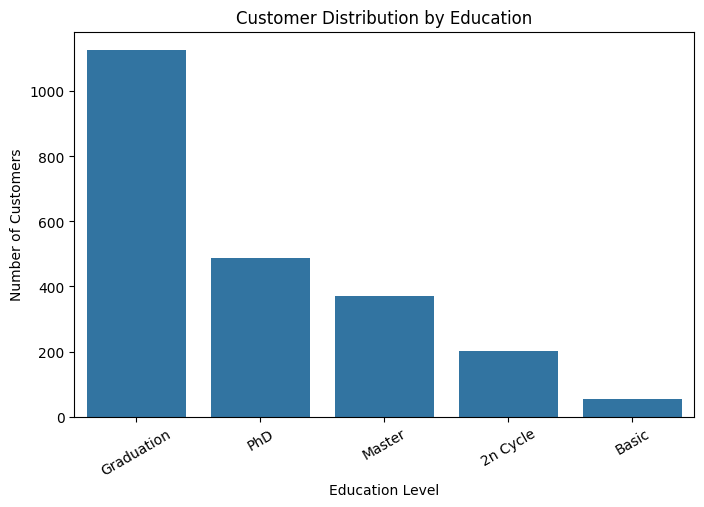

In [16]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="Education",
              order=df["Education"].value_counts().index)

plt.title("Customer Distribution by Education")
plt.xlabel("Education Level")
plt.ylabel("Number of Customers")
plt.xticks(rotation=30)

plt.show()

In [17]:
marital_counts = df["Marital_Status"].value_counts()

print("Customers by Marital Status:")
print(marital_counts)

Customers by Marital Status:
Marital_Status
Married     864
Together    580
Single      480
Divorced    232
Widow        77
Alone         3
Absurd        2
YOLO          2
Name: count, dtype: int64


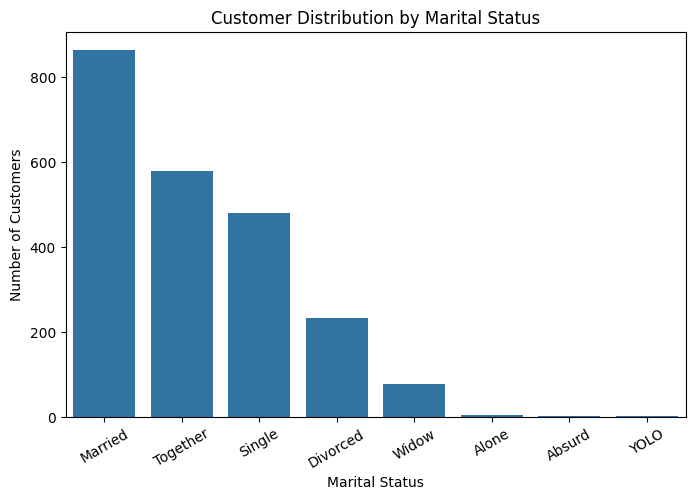

In [18]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="Marital_Status",
              order=df["Marital_Status"].value_counts().index)

plt.title("Customer Distribution by Marital Status")
plt.xlabel("Marital Status")
plt.ylabel("Number of Customers")
plt.xticks(rotation=30)

plt.show()

In [19]:
correlation = df.corr(numeric_only=True)

print(correlation)

                           ID  Year_Birth    Income   Kidhome  Teenhome  \
ID                   1.000000    0.000028  0.012996  0.002406 -0.002580   
Year_Birth           0.000028    1.000000 -0.160899  0.230176 -0.352111   
Income               0.012996   -0.160899  1.000000 -0.425326  0.018965   
Kidhome              0.002406    0.230176 -0.425326  1.000000 -0.036133   
Teenhome            -0.002580   -0.352111  0.018965 -0.036133  1.000000   
Recency             -0.046524   -0.019871 -0.004061  0.008827  0.016198   
MntWines            -0.022878   -0.157773  0.576903 -0.496297  0.004846   
MntFruits            0.004600   -0.017917  0.428791 -0.372581 -0.176764   
MntMeatProducts     -0.004437   -0.030872  0.577805 -0.437129 -0.261160   
MntFishProducts     -0.024475   -0.041625  0.437564 -0.387644 -0.204187   
MntSweetProducts    -0.007642   -0.018133  0.436131 -0.370673 -0.162475   
MntGoldProds        -0.013438   -0.061818  0.321938 -0.349595 -0.021725   
NumDealsPurchases   -0.03

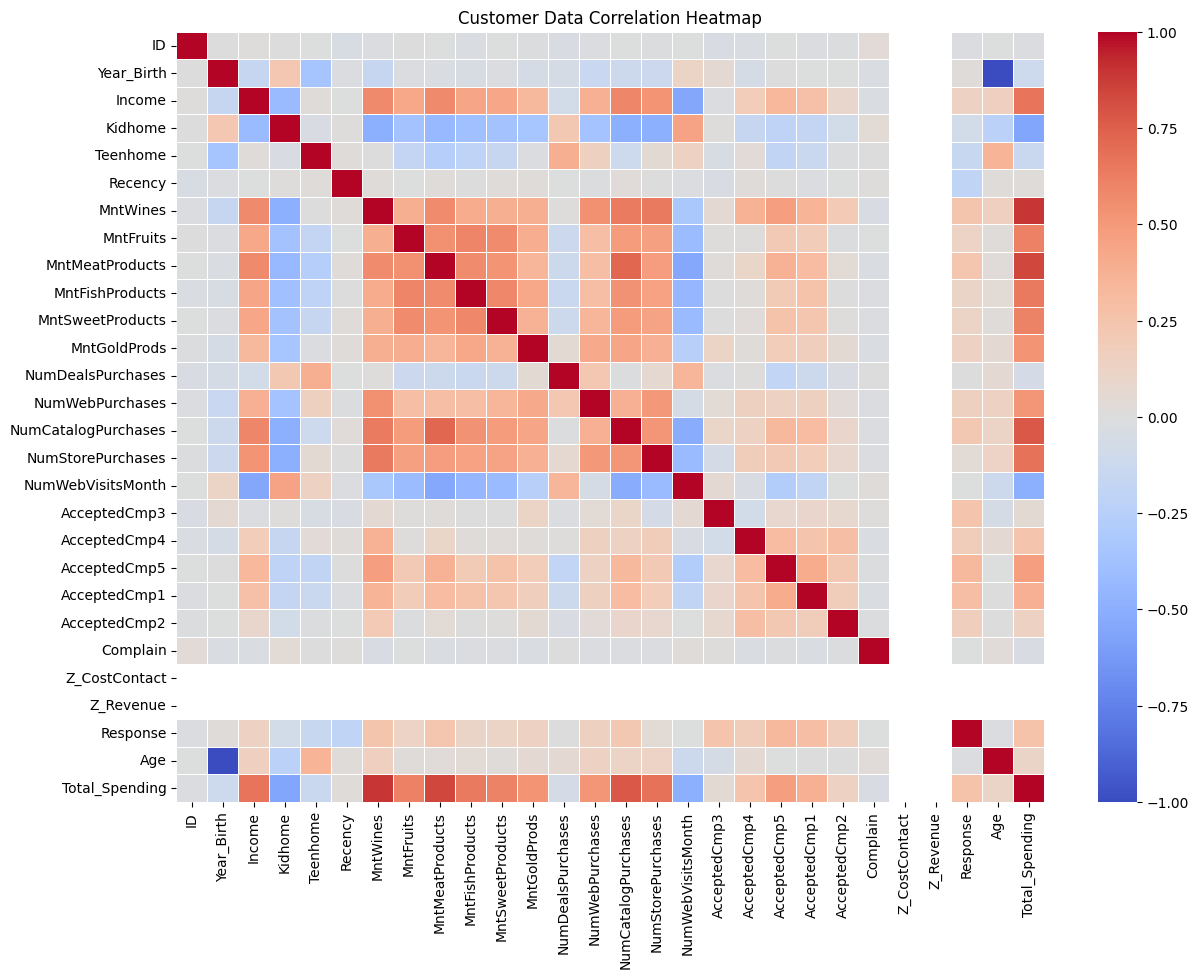

In [20]:
plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation,
    cmap="coolwarm",
    annot=False,
    linewidths=0.5
)

plt.title("Customer Data Correlation Heatmap")
plt.show()

In [21]:
spending_correlation = correlation["Total_Spending"].sort_values(
    ascending=False
)

print(spending_correlation)

Total_Spending         1.000000
MntWines               0.891839
MntMeatProducts        0.842965
NumCatalogPurchases    0.778577
NumStorePurchases      0.674669
Income                 0.664775
MntFishProducts        0.642818
MntFruits              0.614229
MntSweetProducts       0.603016
MntGoldProds           0.524262
NumWebPurchases        0.519837
AcceptedCmp5           0.470058
AcceptedCmp1           0.381523
Response               0.265298
AcceptedCmp4           0.253290
AcceptedCmp2           0.135813
Age                    0.111306
AcceptedCmp3           0.053385
Recency                0.020433
ID                    -0.018054
Complain              -0.037058
NumDealsPurchases     -0.065112
Year_Birth            -0.111306
Teenhome              -0.138384
NumWebVisitsMonth     -0.500218
Kidhome               -0.556669
Z_CostContact               NaN
Z_Revenue                   NaN
Name: Total_Spending, dtype: float64


In [22]:
print("Top 10 Highest Spending Customers:")

display(
    df.nlargest(10, "Total_Spending")[
        ["ID", "Income", "Total_Spending"]
    ]
)

Top 10 Highest Spending Customers:


,ID,Income,Total_Spending
1179,5735,90638.0,2525
1572,5350,90638.0,2525
1492,1763,87679.0,2524
987,4580,75759.0,2486
1052,4475,69098.0,2440
1601,5453,90226.0,2352
1458,10133,93790.0,2349
1288,9010,83151.0,2346
943,5386,94384.0,2302
1301,6024,94384.0,2302


In [23]:
print("========== EDA KEY FINDINGS ==========")

print("\n1. Most Popular Product Category:")
print(category_spending.idxmax())

print("\n2. Most Popular Shopping Channel:")
print(channel_purchases.idxmax())

print("\n3. Highest Campaign Acceptance:")
print(campaign_percentage.idxmax())

print("\n4. Largest Education Group:")
print(education_counts.idxmax())

print("\n5. Most Common Marital Status:")
print(marital_counts.idxmax())

print("\n6. Average Customer Spending:")
print(round(df["Total_Spending"].mean(), 2))

print("\n7. Income and Spending Correlation:")
print(round(df["Income"].corr(df["Total_Spending"]), 3))

print("\n8. Most Common Age Group:")
print(df["Age_Group"].value_counts().idxmax())

========== EDA KEY FINDINGS ==========

1. Most Popular Product Category:
MntWines

2. Most Popular Shopping Channel:
NumStorePurchases

3. Highest Campaign Acceptance:
Response

4. Largest Education Group:
Graduation

5. Most Common Marital Status:
Married

6. Average Customer Spending:
605.8

7. Income and Spending Correlation:
0.665

8. Most Common Age Group:
46-55


In [25]:
import os

os.makedirs("charts", exist_ok=True)


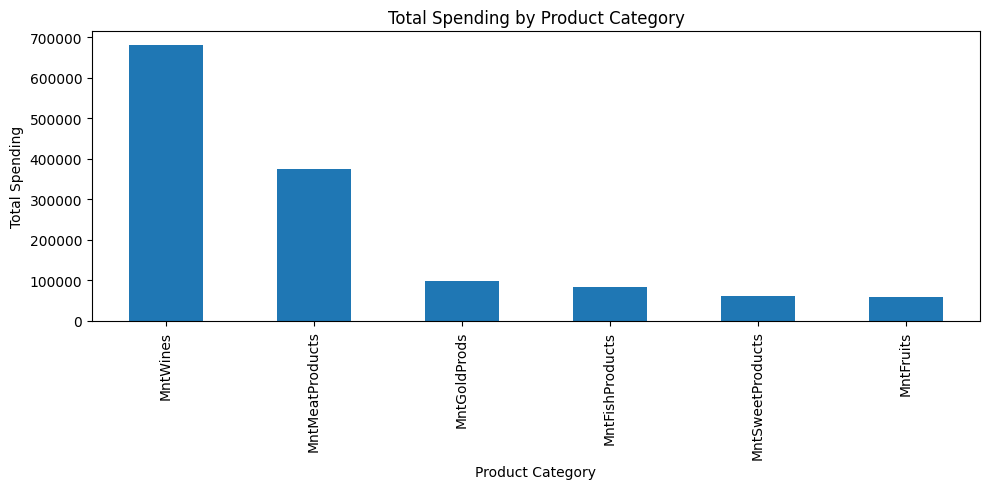

In [26]:
plt.figure(figsize=(10, 5))

category_spending.plot(kind="bar")

plt.title("Total Spending by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Spending")

plt.tight_layout()
plt.savefig("charts/product_spending.png")
plt.show()